# 🛡️ Construction & Industrial Safety PPE Detection System
### College Project: Real-Time Worker Safety Compliance Surveillance
- **Framework:** PyTorch & Ultralytics YOLOv8 (Deep Learning / Computer Vision)
- **Target Hardware:** NVIDIA GeForce RTX 3050 GPU (CUDA Enabled)
- **Classes:** `['No_BreathingApparatus', 'No_Glove', 'No_Goggles', 'No_Harness', 'No_Helmet', 'No_Shoe', 'Person']`

## 1️⃣ Verify PyTorch & CUDA GPU Environment
Check that PyTorch detects our NVIDIA RTX 3050 GPU for accelerated deep learning training.

In [1]:
import os
os.environ["KMP_DUPLICATE_LIB_OK"] = "TRUE"
import torch

print("=" * 50)
print("PyTorch Version  :", torch.__version__)
print("CUDA Available   :", torch.cuda.is_available())
if torch.cuda.is_available():
    print("Active GPU       :", torch.cuda.get_device_name(0))
    print("Total VRAM       :", round(torch.cuda.get_device_properties(0).total_memory / (1024**3), 2), "GB")
print("=" * 50)

PyTorch Version  : 2.5.1+cu121
CUDA Available   : True
Active GPU       : NVIDIA GeForce RTX 3050 Laptop GPU
Total VRAM       : 4.0 GB


## 2️⃣ Inspect Dataset & Classes (`data.yaml`)
Verify the dataset structure (Train, Validation, and Test sets) and inspect all 7 class labels using modern `pathlib`.

In [2]:
from pathlib import Path
import yaml

yaml_path = Path("dataset") / "data.yaml"
with open(yaml_path, "r") as f:
    data_cfg = yaml.safe_load(f)

print("Target Classes (Total =", data_cfg["nc"], "):")
for idx, name in enumerate(data_cfg["names"]):
    print(f"  [{idx}] {name}")

train_imgs = list(Path("dataset/train/images").glob("*.*"))
val_imgs   = list(Path("dataset/valid/images").glob("*.*"))
test_imgs  = list(Path("dataset/test/images").glob("*.*"))

print("\nDataset Breakdown:")
print(f"  Training Images   : {len(train_imgs)}")
print(f"  Validation Images : {len(val_imgs)}")
print(f"  Test Images       : {len(test_imgs)}")
print(f"  Total Dataset     : {len(train_imgs) + len(val_imgs) + len(test_imgs)} images")

Target Classes (Total = 7 ):
  [0] No_BreathingApparatus
  [1] No_Glove
  [2] No_Goggles
  [3] No_Harness
  [4] No_Helmet
  [5] No_Shoe
  [6] Person

Dataset Breakdown:
  Training Images   : 5001
  Validation Images : 1328
  Test Images       : 300
  Total Dataset     : 6629 images


## 3️⃣ Preview Sample Dataset Images
Quickly visualize a few sample raw images from the test set.

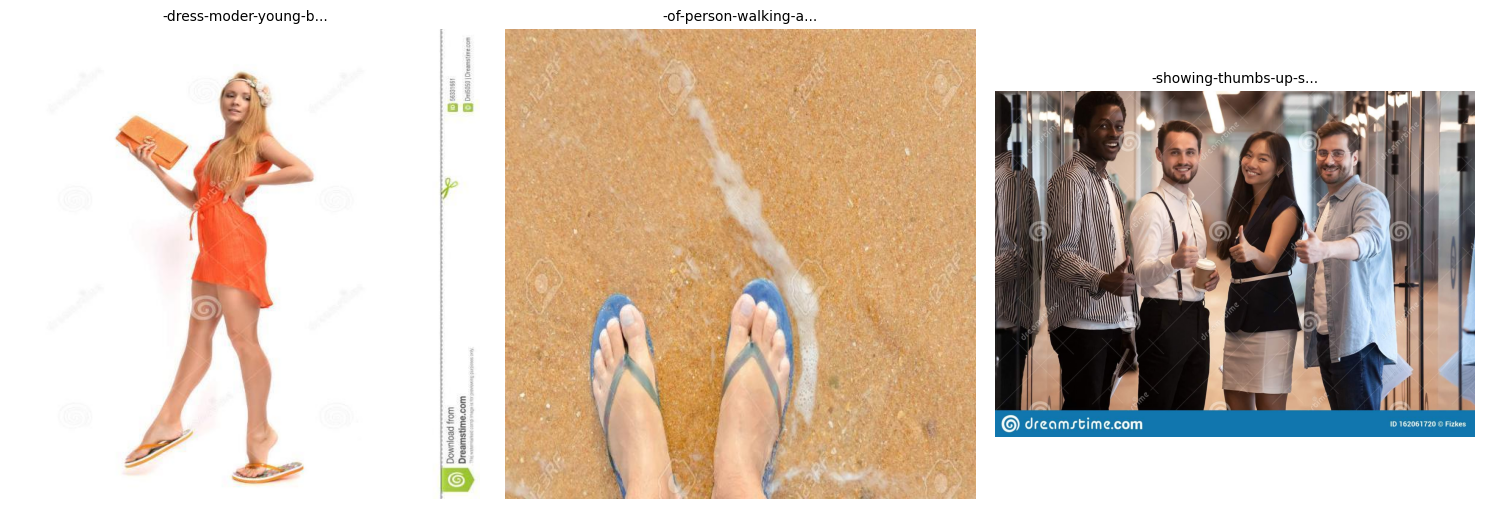

In [3]:
import os
os.environ["KMP_DUPLICATE_LIB_OK"] = "TRUE"
from pathlib import Path
import matplotlib.pyplot as plt
from PIL import Image

sample_files = list(Path("dataset/test/images").glob("*.jpg"))[:3]
fig, axes = plt.subplots(1, 3, figsize=(15, 5))

for ax, img_path in zip(axes, sample_files):
    img = Image.open(img_path)
    ax.imshow(img)
    ax.set_title(img_path.name[:20] + "...", fontsize=10)
    ax.axis("off")

plt.tight_layout()
plt.show()

## 4️⃣ Fine-Tune YOLOv8 Model on GPU
*(Training complete! Model weights are saved at `runs/detect/ppe_yolov8/weights/best.pt`)*

In [ ]:
from pathlib import Path
from ultralytics import YOLO

# 1. Load pretrained YOLOv8n backbone
model = YOLO("yolov8n.pt") #~3 million parameters, sirf ~6 MB size

# 2. Dataset configuration path resolved with pathlib
dataset_yaml = Path("dataset/data.yaml").resolve().as_posix()

# 3. Start Training (live progress bar with epochs will display below)
results = model.train(
    data=dataset_yaml,
    epochs=15,
    imgsz=640,
    batch=16,
    device=0,
    workers=2,
    project="runs/detect",
    name="ppe_yolov8",
    exist_ok=True,
    pretrained=True,
    save=True,
    verbose=True
)

print("\nTraining complete!")
print("Best weights saved at: runs/detect/ppe_yolov8/weights/best.pt")

## 5️⃣ Evaluation Metrics & Training Curves (Confusion Matrix & Accuracy)
Plot the training loss, precision, recall, mAP curves, and confusion matrix.

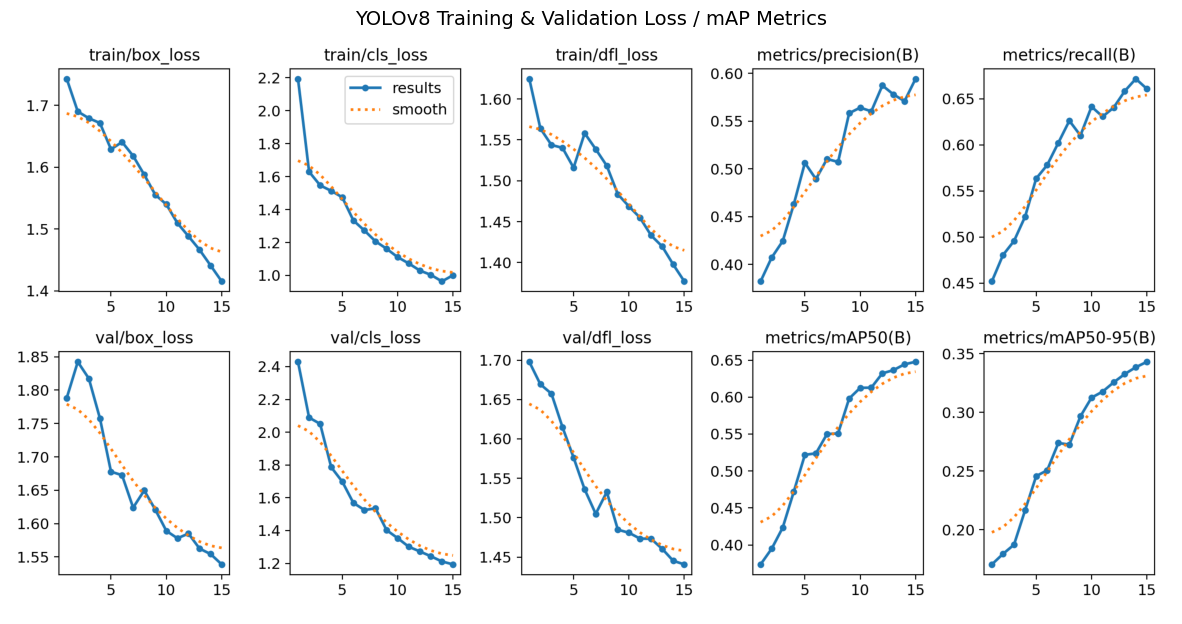

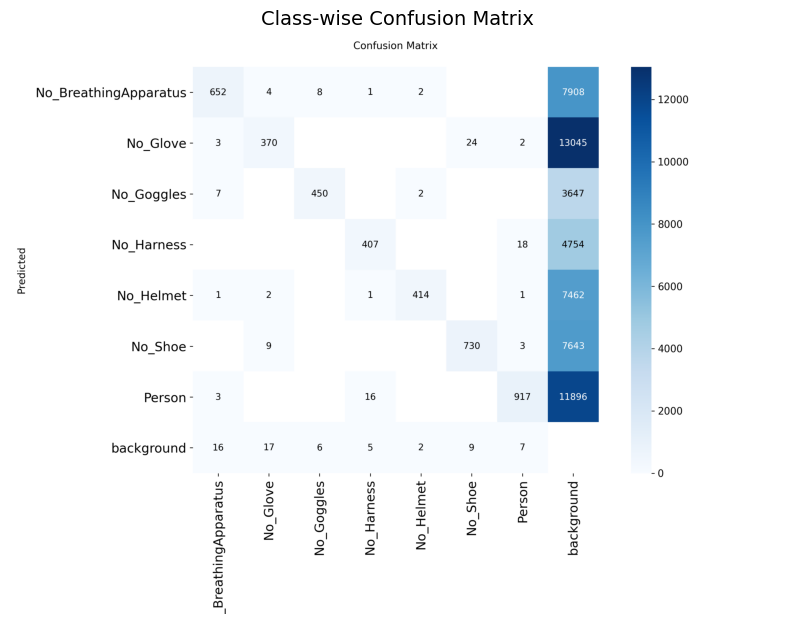

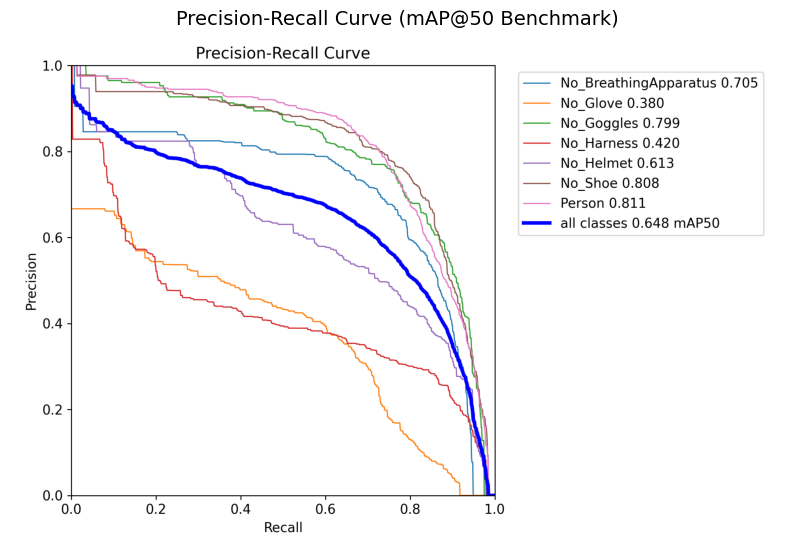

In [4]:
from pathlib import Path
import matplotlib.pyplot as plt
from PIL import Image

# 1. Plot Training Loss and mAP Curves using rglob (recursive search)
possible_results = list(Path("runs").rglob("results.png"))
if possible_results:
    plt.figure(figsize=(15, 9))
    plt.imshow(Image.open(possible_results[0]))
    plt.axis("off")
    plt.title("YOLOv8 Training & Validation Loss / mAP Metrics", fontsize=14)
    plt.show()

# 2. Plot Confusion Matrix
possible_cm = list(Path("runs").rglob("confusion_matrix.png"))
if possible_cm:
    plt.figure(figsize=(10, 8))
    plt.imshow(Image.open(possible_cm[0]))
    plt.axis("off")
    plt.title("Class-wise Confusion Matrix", fontsize=14)
    plt.show()

# 3. Plot Precision-Recall Curve (PR Curve)
possible_pr = list(Path("runs").rglob("BoxPR_curve.png"))
if possible_pr:
    plt.figure(figsize=(10, 7))
    plt.imshow(Image.open(possible_pr[0]))
    plt.axis("off")
    plt.title("Precision-Recall Curve (mAP@50 Benchmark)", fontsize=14)
    plt.show()

## 6️⃣ Quantitative Evaluation on Unseen Test Dataset (`model.val()`)
Calculate the exact test accuracy scores: Precision, Recall, and mAP@50 across all classes.

In [5]:
from pathlib import Path
from ultralytics import YOLO

# Load best trained model
candidates = list(Path("runs").rglob("best.pt"))
best_weights = str(candidates[0]) if candidates else "yolov8n.pt"
eval_model = YOLO(best_weights)

dataset_yaml = Path("dataset/data.yaml").resolve().as_posix()

print("=" * 65)
print("  RUNNING QUANTITATIVE VALIDATION ON UNSEEN TEST DATASET")
print("=" * 65)
metrics = eval_model.val(data=dataset_yaml, split="test", device=0)

print("\n" + "=" * 65)
print("              OVERALL MODEL ACCURACY BENCHMARKS")
print("=" * 65)
print(f" 🎯 Mean Precision (P)         : {metrics.box.mp * 100:.2f}%")
print(f" 🎯 Mean Recall (R)            : {metrics.box.mr * 100:.2f}%")
print(f" 🏆 Detection Accuracy (mAP@50): {metrics.box.map50 * 100:.2f}%")
print(f" 📊 Overall mAP (mAP@50-95)    : {metrics.box.map * 100:.2f}%")
print("=" * 65)

  RUNNING QUANTITATIVE VALIDATION ON UNSEEN TEST DATASET
Ultralytics 8.4.183  Python-3.10.20 torch-2.5.1+cu121 CUDA:0 (NVIDIA GeForce RTX 3050 Laptop GPU, 4096MiB)
Model summary (fused): 73 layers, 3,134,165 parameters, 0 gradients, 8.6 GFLOPs
WARNING val: Slow image access detected (ping: 0.3±0.3 ms, read: 6.8±2.8 MB/s, size: 61.8 KB). Use local storage instead of remote/mounted storage for better performance. See https://docs.ultralytics.com/guides/model-training-tips
val: Scanning C:\Users\sachi\Desktop\computer_vision_project\dataset\test\labels... 300 images, 113 backgrounds, 4 corrupt: 100% ━━━━━━━━━━━━ 300/300 365.0it/s 0.8s0.0s
val: C:\Users\sachi\Desktop\computer_vision_project\dataset\test\images\1614915785_shutterstock_1050584231-750x500_jpg.rf.587ce78585f997f748989696f237727d.jpg: ignoring corrupt image/label: labels mix segment and detection rows
val: C:\Users\sachi\Desktop\computer_vision_project\dataset\test\images\group-of-seated-people-in-a-circle-1024x585_jpg.rf.b47e7

## 7️⃣ Test Inference on Sample Image with Violation Reporting
Run our fine-tuned `best.pt` model on an unseen test image and display detected safety violations.

 Loaded Fine-Tuned PPE Model: runs\detect\ppe_yolov8\weights\best.pt

image 1/1 c:\Users\sachi\Desktop\computer_vision_project\dataset\test\images\-dress-moder-young-beautiful-caucasian-red-hair-flops-modern-clutch-56331661_jpg.rf.baeb13147b4085d3a4bced603bde85a3.jpg: 640x640 1 No_Goggles, 1 No_Helmet, 2 No_Shoes, 39.5ms
Speed: 7.1ms preprocess, 39.5ms inference, 4.7ms postprocess per image at shape (1, 3, 640, 640)


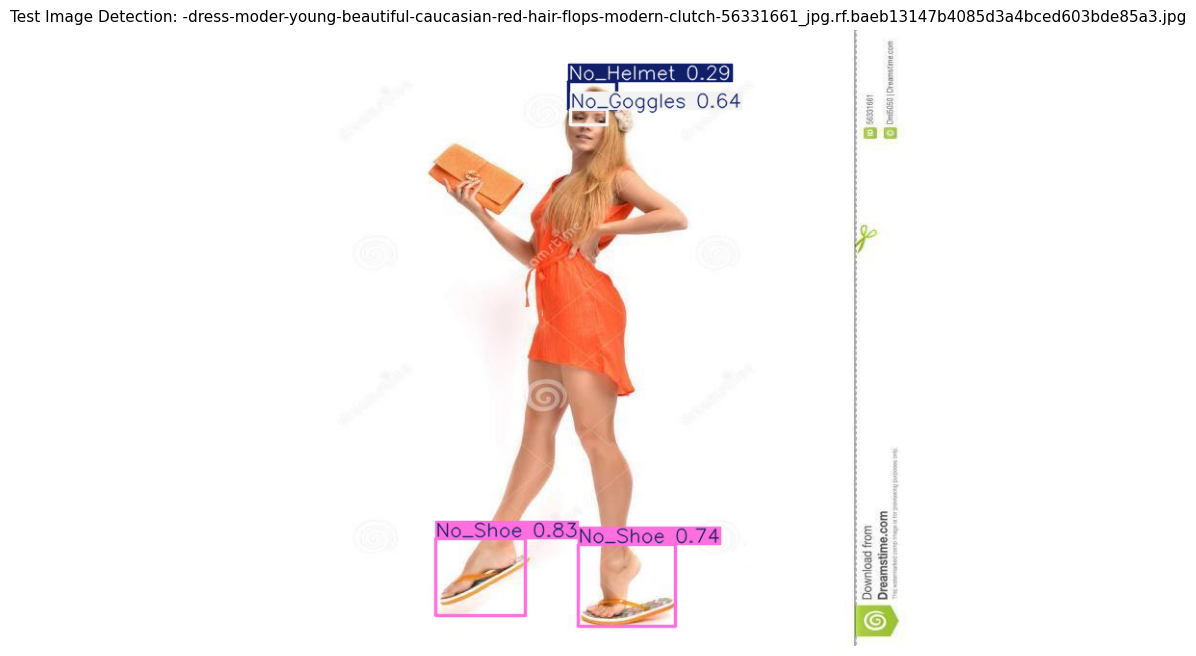


        SAFETY COMPLIANCE AUDIT REPORT
 🚨 [VIOLATION] No_Shoe                  | Confidence: 82.6%
 🚨 [VIOLATION] No_Shoe                  | Confidence: 74.1%
 🚨 [VIOLATION] No_Goggles               | Confidence: 64.3%
 🚨 [VIOLATION] No_Helmet                | Confidence: 29.4%
------------------------------------------------------------
 🚨 SITE STATUS: NON-COMPLIANT (4 Safety Breaches Detected)


In [6]:
from pathlib import Path
import matplotlib.pyplot as plt
from PIL import Image
from ultralytics import YOLO

# Auto-locate best.pt weights
candidates = list(Path("runs").rglob("best.pt"))
best_weights = str(candidates[0]) if candidates else "yolov8n.pt"
print(f" Loaded Fine-Tuned PPE Model: {best_weights}")
eval_model = YOLO(best_weights)

# Pick a test image from dataset using pathlib
test_images = list(Path("dataset/test/images").glob("*.jpg"))
if test_images:
    sample_test = test_images[0] # Path object
    results = eval_model.predict(source=str(sample_test), conf=0.25)
    
    # Visualize detection
    annotated_rgb = results[0].plot()[:, :, ::-1] # BGR to RGB
    plt.figure(figsize=(10, 8))
    plt.imshow(annotated_rgb)
    plt.axis("off")
    plt.title(f"Test Image Detection: {sample_test.name}", fontsize=11)
    plt.show()
    
    # Print Safety Compliance Audit Report
    print("\n" + "=" * 60)
    print("        SAFETY COMPLIANCE AUDIT REPORT")
    print("=" * 60)
    violations = []
    for box in results[0].boxes:
        cname = results[0].names[int(box.cls[0].item())]
        conf = float(box.conf[0].item())
        if cname.startswith("No_"):
            violations.append(f"{cname} ({conf:.1%})")
            print(f" 🚨 [VIOLATION] {cname:<24} | Confidence: {conf:.1%}")
        else:
            print(f" 🟢 [ENTITY]    {cname:<24} | Confidence: {conf:.1%}")
            
    print("-" * 60)
    if violations:
        print(f" 🚨 SITE STATUS: NON-COMPLIANT ({len(violations)} Safety Breaches Detected)")
    else:
        print(" 🟢 SITE STATUS: 100% COMPLIANT (No safety violations detected)")
    print("=" * 60)

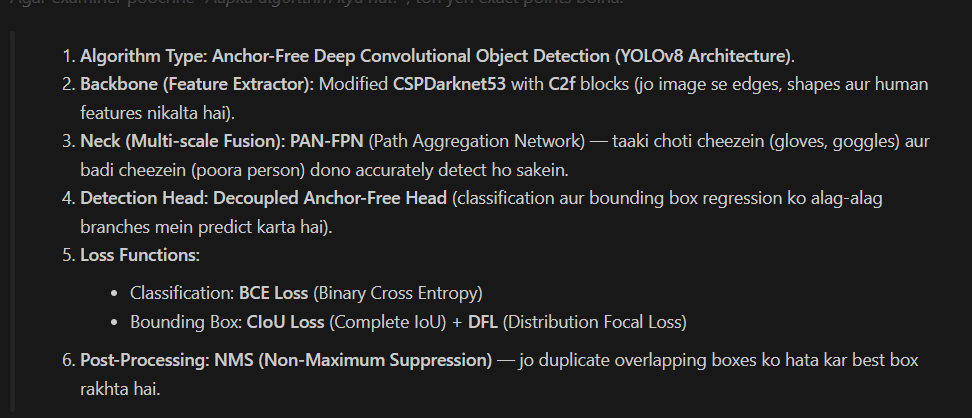